In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('AirQualityUCI.csv', delimiter=';', decimal=',')
df.head()


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [ ]:
df.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,0.0,0.0
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604,NaN,NaN
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670,NaN,NaN
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,NaN,NaN
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300,NaN,NaN
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800,NaN,NaN
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200,NaN,NaN
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), object(2)
memory usage: 1.2+ MB


In [ ]:
from sklearn.impute import SimpleImputer

df = df.dropna(how='all').dropna(axis=1, how='all')
df_cleaned = df.replace(-200, np.nan)


num_cols = df_cleaned.select_dtypes(include='number').columns

imputer = SimpleImputer(strategy='median')
df_imputed = df_cleaned.copy()
df_imputed[num_cols] = imputer.fit_transform(df_cleaned[num_cols])

df_imputed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

cat_cols = ['Date', 'Time']
num_cols   = [c for c in df_imputed.columns if c not in cat_cols]
print('Numerical  :', num_cols)
print('Categorical:', cat_cols)

num_pipe = Pipeline([
    # missing values were already imputed in df_imputed (cell 3)
    ('scaler',  StandardScaler()),
])

cat_pipe = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

# One ColumnTransformer routes each column group through its own pipeline
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
])

df_prepared = preprocessor.fit_transform(df_imputed)
print('Prepared matrix shape:', df_prepared.shape)

Numerical  : ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Categorical: ['Date', 'Time']


In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

df_clf = df_imputed.copy()
df_clf['air_quality'] = pd.qcut(df_clf['CO(GT)'], q=3, labels=[0, 1, 2]).astype(int)

features = [c for c in df_clf.columns if c not in ['Date', 'Time', 'CO(GT)', 'NMHC(GT)', 'air_quality']]
X_train, X_test, y_train, y_test = train_test_split(df_clf[features], df_clf['air_quality'], random_state=42)

preprocessing = ColumnTransformer([('num', clone(num_pipe), features)])  # scales the numeric features; fit on train only
X_train_prep = preprocessing.fit_transform(X_train)
X_test_prep = preprocessing.transform(X_test)

In [ ]:
import time
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

start = time.time()
softmax_reg = LogisticRegression(C=30, random_state=42).fit(X_train_prep, y_train)
softmax_time = time.time() - start
y_pred = softmax_reg.predict(X_test_prep)

print("Iterations:", softmax_reg.n_iter_[0], f"| time: {softmax_time:.3f}s")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4), "| macro F1:", round(f1_score(y_test, y_pred, average='macro'), 4))

Iterations: 73 | time: 0.254s
Accuracy: 0.8603 | macro F1: 0.8611


In [ ]:
rows = []
for loss in ['log_loss', 'hinge', 'modified_huber']:
    for eta0 in [0.001, 0.01, 0.1]:
        start = time.time()
        clf = SGDClassifier(loss=loss, penalty=None, learning_rate='constant', eta0=eta0,
                            max_iter=1000, tol=1e-5, n_iter_no_change=5, random_state=42)
        clf.fit(X_train_prep, y_train)
        y_pred = clf.predict(X_test_prep)
        rows.append({'model': f'SGD {loss}', 'eta0': eta0, 'epochs': clf.n_iter_,
                     'fit_time_s': round(time.time() - start, 3),
                     'accuracy': round(accuracy_score(y_test, y_pred), 4),
                     'macro_f1': round(f1_score(y_test, y_pred, average='macro'), 4)})

y_pred = softmax_reg.predict(X_test_prep)
rows.append({'model': 'Softmax (LogisticRegression)', 'eta0': '-', 'epochs': softmax_reg.n_iter_[0],
             'fit_time_s': round(softmax_time, 3), 'accuracy': round(accuracy_score(y_test, y_pred), 4),
             'macro_f1': round(f1_score(y_test, y_pred, average='macro'), 4)})
pd.DataFrame(rows)

,model,eta0,epochs,fit_time_s,accuracy,macro_f1
0,SGD log_loss,0.001,655,0.902,0.8603,0.8610
1,SGD log_loss,0.01,118,0.182,0.8541,0.8550
2,SGD log_loss,0.1,26,0.063,0.8603,0.8608
3,SGD hinge,0.001,392,0.254,0.8551,0.8566
4,SGD hinge,0.01,77,0.049,0.8572,0.8585
5,SGD hinge,0.1,21,0.021,0.8405,0.8413
6,SGD modified_huber,0.001,91,0.078,0.8567,0.8578
7,SGD modified_huber,0.01,26,0.031,0.8583,0.8590
8,SGD modified_huber,0.1,17,0.020,0.8364,0.8348
9,Softmax (LogisticRegression),-,73,0.254,0.8603,0.8611


In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

df_reg = df_imputed.copy()
features = [c for c in df_reg.columns if c not in ['Date', 'Time', 'CO(GT)', 'NMHC(GT)']]
X_train, X_test, y_train, y_test = train_test_split(df_reg[features], df_reg['CO(GT)'], random_state=42)

preprocessing = ColumnTransformer([('num', clone(num_pipe), features)])
X_train_prep = preprocessing.fit_transform(X_train)
X_test_prep = preprocessing.transform(X_test)
print("Target std:", round(y_train.std(), 4))

Target std: 1.4586


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import root_mean_squared_error

lin_reg = LinearRegression().fit(X_train_prep, y_train)
print("Train RMSE:", round(root_mean_squared_error(y_train, lin_reg.predict(X_train_prep)), 4))
print("Test RMSE :", round(root_mean_squared_error(y_test, lin_reg.predict(X_test_prep)), 4))
pd.Series(lin_reg.coef_, index=features).round(3)

Train RMSE: 0.4956
Test RMSE : 0.4675


,0
PT08.S1(CO),0.258
C6H6(GT),0.543
PT08.S2(NMHC),-0.014
NOx(GT),0.561
PT08.S3(NOx),0.015
NO2(GT),0.112
PT08.S4(NO2),0.462
PT08.S5(O3),-0.214
T,-0.219
RH,-0.137


In [ ]:
ridge_coefs = {'alpha=0 (Linear)': lin_reg.coef_}
ridge_rmse = {'alpha=0 (Linear)': root_mean_squared_error(y_test, lin_reg.predict(X_test_prep))}
for alpha in [0.1, 1, 10, 100, 1000, 10000]:
    ridge_reg = Ridge(alpha=alpha, random_state=42).fit(X_train_prep, y_train)
    ridge_coefs[f'alpha={alpha}'] = ridge_reg.coef_
    ridge_rmse[f'alpha={alpha}'] = root_mean_squared_error(y_test, ridge_reg.predict(X_test_prep))

ridge_table = pd.DataFrame(ridge_coefs, index=features).T.round(3) + 0.0
ridge_table.insert(0, 'test_rmse', pd.Series(ridge_rmse).round(4))
ridge_table['n_zero_coefs'] = [(c == 0).sum() for c in ridge_coefs.values()]
ridge_table

,test_rmse,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,n_zero_coefs
alpha=0 (Linear),0.4675,0.258,0.543,-0.014,0.561,0.015,0.112,0.462,-0.214,-0.219,-0.137,-0.057,0
alpha=0.1,0.4675,0.258,0.543,-0.013,0.561,0.015,0.112,0.462,-0.214,-0.219,-0.137,-0.057,0
alpha=1,0.4675,0.258,0.540,-0.009,0.560,0.016,0.112,0.461,-0.214,-0.219,-0.137,-0.057,0
alpha=10,0.4677,0.257,0.516,0.027,0.556,0.022,0.112,0.450,-0.209,-0.213,-0.132,-0.056,0
alpha=100,0.4702,0.246,0.426,0.166,0.520,0.049,0.118,0.383,-0.162,-0.166,-0.094,-0.060,0
alpha=1000,0.4981,0.207,0.326,0.242,0.374,0.028,0.144,0.238,0.036,-0.061,-0.027,-0.060,0
alpha=10000,0.6446,0.161,0.191,0.176,0.185,-0.087,0.133,0.123,0.138,-0.013,-0.002,-0.020,0


In [ ]:
lasso_coefs, lasso_rmse = {}, {}
for alpha in [0.001, 0.01, 0.05, 0.1, 0.3, 1]:
    lasso_reg = Lasso(alpha=alpha, random_state=42).fit(X_train_prep, y_train)
    lasso_coefs[f'alpha={alpha}'] = lasso_reg.coef_
    lasso_rmse[f'alpha={alpha}'] = root_mean_squared_error(y_test, lasso_reg.predict(X_test_prep))

lasso_table = pd.DataFrame(lasso_coefs, index=features).T.round(3) + 0.0
lasso_table.insert(0, 'test_rmse', pd.Series(lasso_rmse).round(4))
lasso_table['n_zero_coefs'] = [(c == 0).sum() for c in lasso_coefs.values()]
lasso_table

,test_rmse,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,n_zero_coefs
alpha=0.001,0.4676,0.251,0.536,0.0,0.556,0.016,0.110,0.450,-0.200,-0.203,-0.125,-0.063,1
alpha=0.01,0.4744,0.186,0.554,0.0,0.513,0.007,0.098,0.359,-0.069,-0.044,-0.018,-0.134,1
alpha=0.05,0.4980,0.181,0.710,0.0,0.408,0.000,0.097,0.075,0.000,0.000,0.000,0.000,6
alpha=0.1,0.5143,0.187,0.762,0.0,0.368,0.000,0.056,0.000,0.000,0.000,0.000,0.000,7
alpha=0.3,0.6124,0.128,0.696,0.0,0.294,0.000,0.000,0.000,0.000,0.000,0.000,0.000,8
alpha=1,1.1794,0.000,0.305,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,10


In [ ]:
for name, coefs in lasso_coefs.items():
    print(f"{name:12s} kept: {[f for f, c in zip(features, coefs) if c != 0]}")

alpha=0.001  kept: ['PT08.S1(CO)', 'C6H6(GT)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
alpha=0.01   kept: ['PT08.S1(CO)', 'C6H6(GT)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
alpha=0.05   kept: ['PT08.S1(CO)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'PT08.S4(NO2)']
alpha=0.1    kept: ['PT08.S1(CO)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']
alpha=0.3    kept: ['PT08.S1(CO)', 'C6H6(GT)', 'NOx(GT)']
alpha=1      kept: ['C6H6(GT)']


Task 1 & 8: Proof of Billing
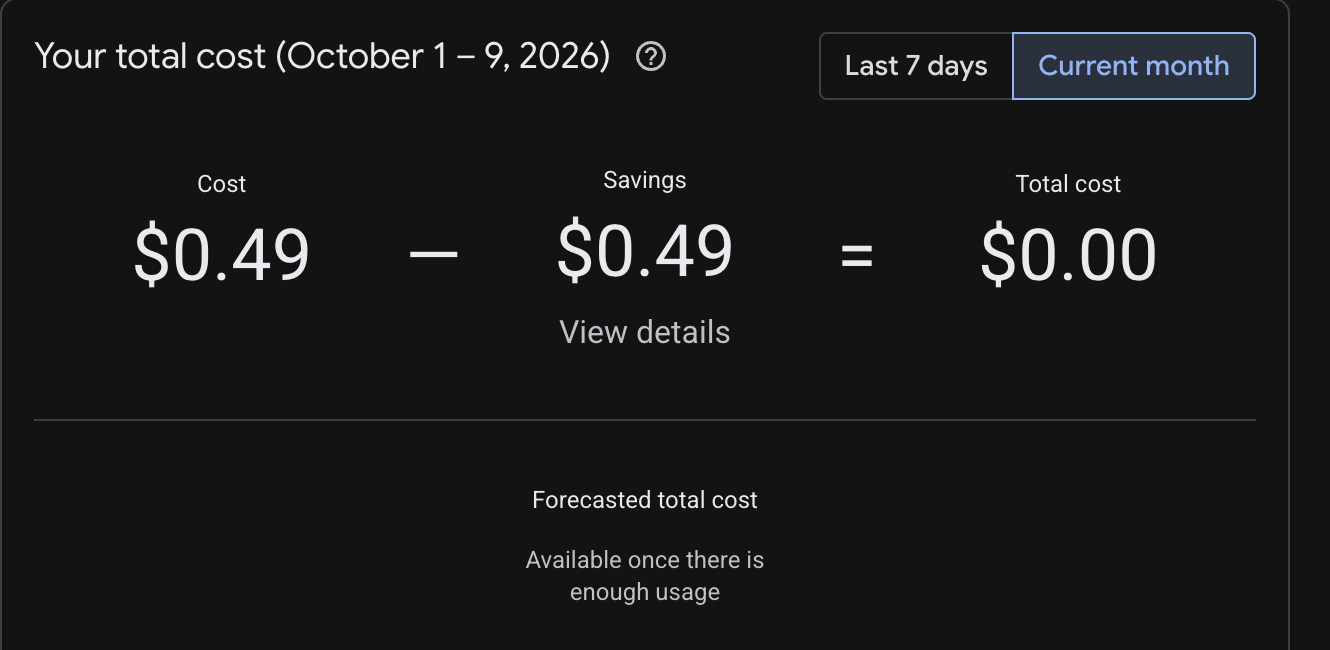